# Step 1 — Hand-tune the supra-threshold ERP

First stage of the ERP tuning pipeline for the `duecker_ET_model`:

1. **Step 1 — hand-tune (this notebook):** manually set the evoked-drive timing and
   synaptic weights until the simulated dipole qualitatively matches the measured ERP.
   This provides the starting point for the optimiser.
2. **Step 2 — optimise (`optim_ERP_cma.py`):** refine those drive parameters with
   CMA-ES against the experimental waveform (run on the cluster via `optim_ERP_cma.sh`).
3. **Step 3 — inspect results (`optim_ERP_results.ipynb`):** load the optimiser
   checkpoint and analyse the fitted ERP.

**Target:** the S1 supra-threshold (detected) MEG ERP, `data/hnn-data/MEG_detection_data/S1_SupraT.txt`.


## Environment setup (OSCAR / MPI only)

Cluster-specific MPI/library paths. Left commented — only uncomment when running
on OSCAR.

In [1]:
# ONLY NECESSARY WHEN RUNNING ON OSCAR (uncomment)

import os

# Use conda's newer libstdc++ instead of the system one
conda_lib = os.path.expanduser("~/.conda/envs/hnn-core-env/lib")
ld_path = os.environ.get("LD_LIBRARY_PATH", "")
os.environ["LD_LIBRARY_PATH"] = f"{conda_lib}:{ld_path}"

# UCX settings (from before)
os.environ["UCX_TLS"] = "tcp,self,sm"
os.environ["UCX_NET_DEVICES"] = "all"


# MPI paths
mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
mpi_lib = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/lib"
if mpi_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"
if mpi_lib not in ld_path:
    os.environ["LD_LIBRARY_PATH"] = f"{mpi_lib}:{os.environ['LD_LIBRARY_PATH']}"


import sys
# Add MPI bin directory to PATH
mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
if mpi_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"

# print("Updated PATH to include MPI")
# print("MPI location:", mpi_bin)

import os
print("PATH:", os.environ.get('PATH', 'NOT SET'))
print("Which mpiexec:")
import subprocess
result = subprocess.run(['which', 'mpiexec'], capture_output=True, text=True)
print(result.stdout if result.returncode == 0 else "mpiexec not found")

PATH: /oscar/rt/sw/external/hpcx-mpi/2.25.1/bin:/Users/katharinaduecker/miniconda3/envs/hnn-core-env/bin:/Users/katharinaduecker/.local/bin:/Users/katharinaduecker/miniconda3/envs/hnn-core-env/bin:/Users/katharinaduecker/miniconda3/condabin:/opt/homebrew/bin:/opt/homebrew/sbin:/usr/local/bin:/System/Cryptexes/App/usr/bin:/usr/bin:/bin:/usr/sbin:/sbin:/var/run/com.apple.security.cryptexd/codex.system/bootstrap/usr/local/bin:/var/run/com.apple.security.cryptexd/codex.system/bootstrap/usr/bin:/var/run/com.apple.security.cryptexd/codex.system/bootstrap/usr/appleinternal/bin:/pkg/env/global/bin:/opt/X11/bin:/Library/Apple/usr/bin:/Library/TeX/texbin
Which mpiexec:
/Users/katharinaduecker/miniconda3/envs/hnn-core-env/bin/mpiexec



## Imports and plotting setup

In [2]:
from hnn_tuning import REPO_ROOT
pth = str(REPO_ROOT)


In [3]:
import os
import os.path as op

import matplotlib.pyplot as plt
import pickle

from hnn_core.hnn_io import write_network_configuration, read_network_configuration
from hnn_core.dipole import average_dipoles
from hnn_core.dipole import _rmse, average_dipoles

import sys
sys.path.append(pth)

import hnn_core

from hnn_core import duecker_ET_model, simulate_dipole, read_dipole, MPIBackend, JoblibBackend

from hnn_core.optimization import Optimizer
import numpy as np
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
from hnn_tuning import results_dir

figpth = results_dir('network_sim', 'ERP')

# The number of cores may need modifying depending on your current machine.
cols = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
plt.rcParams['pdf.fonttype'] = 'truetype'
import matplotlib

col_lines = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
cmap_lines = matplotlib.colors.ListedColormap(col_lines)
# Set global font sizes
plt.rcParams['font.size'] = 12          # Default text size
plt.rcParams['axes.titlesize'] = 12      # Title size
plt.rcParams['axes.labelsize'] = 12      # Axis labels (xlabel, ylabel)
plt.rcParams['xtick.labelsize'] = 12    # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 12     # Y-axis tick labels
plt.rcParams['legend.fontsize'] = 12     # Legend text

n_procs=3
cm_neurons = np.array([[218,166,156], [164,30,79], [119,161,187],[92,114,183]])/255

## Load the experimental target ERP

Read the measured supra-threshold dipole and set the simulation length (`tstop`) to
match it. `scale_factor` and `smooth_window_len` bring the model dipole onto the same
scale/smoothness as the data for comparison below.

In [4]:
exp_dpl = read_dipole(op.join(pth, 'data', 'hnn-data', 'MEG_detection_data', 'S1_SupraT.txt'))

tstop = exp_dpl.times[-1]
scale_factor = 1000
smooth_window_len = 5

## Hand-tuned evoked drives and simulation

Build the network, then add the canonical ERP drive sequence — an early proximal drive
(`prox1`, ~15 ms), a distal drive (`dist1`, ~60 ms), and a late proximal drive
(`prox2`, ~100 ms). The AMPA/NMDA weights, timing (`mu`/`sigma`), and synaptic delays
below are the hand-tuned values; these are what Step 2 optimises. A laminar electrode
array (`probe1`) is added for current-source inspection. `bsl_cor='duecker'` applies the
model's baseline correction.

In [5]:
# def convert_log10(weights):

#     for key, val in weights.items():
#         print(f'{key}: {np.log10(val)}')

# convert_log10(weights_nmda_p2)

In [6]:
net = duecker_ET_model()
net.set_cell_positions(inplane_distance=30.)
depths = list(list(range(-500,2200,100)))
electrode_pos = [(135, 135, dep) for dep in depths]
net.add_electrode_array('probe1', electrode_pos)
weights_ampa_p1 = {'L2_inhibitory': 0.015, 
                   'L2_pyramidal': 0.035,
                   'L5_inhibitory': 0, 
                   'L5_pyramidal': 0.015}
weights_nmda_p1 = {'L2_inhibitory': 0.01, 'L2_pyramidal': 0.025,
                   'L5_inhibitory': 0.0, 'L5_pyramidal': .01}
synaptic_delays_prox = {'L2_inhibitory': 0.1, 'L2_pyramidal': .1,
                        'L5_inhibitory': 1., 'L5_pyramidal': 1.}

net.add_evoked_drive('prox1', mu=15.13, sigma=3.1, numspikes=1, weights_ampa=weights_ampa_p1,
    weights_nmda=weights_nmda_p1, location='proximal', synaptic_delays=synaptic_delays_prox)

weights_ampa_d1 = {'L2_inhibitory': 3e-6, 'L2_pyramidal': 0.0001, 'L5_pyramidal': 2.5}
weights_nmda_d1 = {'L2_inhibitory': 8e-12, 'L2_pyramidal': 0.0001, 'L5_pyramidal': 0.04}
synaptic_delays_dist = {'L2_inhibitory': 0.5, 'L2_pyramidal': 0.5,'L5_pyramidal': .5}

net.add_evoked_drive('dist1', mu=60, sigma=3.7, numspikes=4, weights_ampa=weights_ampa_d1,
    weights_nmda=weights_nmda_d1, location='distal', synaptic_delays=synaptic_delays_dist)

weights_ampa_p2 = {'L2_inhibitory': 0.0, 'L2_pyramidal':0.014,
                   'L5_inhibitory': 2e-7, 'L5_pyramidal': 0.34}
weights_nmda_p2 = {'L2_inhibitory': 0.0, 'L2_pyramidal': 2e-5,
                   'L5_inhibitory': 5.7e-8, 'L5_pyramidal': 0.0027}
synaptic_delays_prox = {'L2_inhibitory': 0.1, 'L2_pyramidal': .1,
                        'L5_inhibitory': 1., 'L5_pyramidal': 1.}
net.add_evoked_drive('prox2', mu=122, sigma=13.4, numspikes=3, weights_ampa=weights_ampa_p2,
    weights_nmda=weights_nmda_p2, location='proximal', synaptic_delays=synaptic_delays_prox)


with JoblibBackend(n_jobs=n_procs):
    dpl = simulate_dipole(net, tstop=tstop, n_trials=3,bsl_cor='duecker')


/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/network.py:887: FutureWarning: `Network.set_cell_positions` will be deprecated in favor of `Network.update_cell_positions` in future releases.
  warnings.warn(


Joblib will run 3 trial(s) in parallel by distributing trials over 3 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Building the NEURON model
Building the NEURON model
[Done]
Trial 2: 0.03 ms...
[Done]
[Done]
Trial 1: 0.03 ms...
Trial 3: 0.03 ms...
Trial 2: 10.0 ms...
Trial 3: 10.0 ms...
Trial 1: 10.0 ms...
Trial 2: 20.0 ms...
Trial 3: 20.0 ms...
Trial 1: 20.0 ms...
Trial 2: 30.0 ms...
Trial 3: 30.0 ms...
Trial 1: 30.0 ms...
Trial 2: 40.0 ms...
Trial 3: 40.0 ms...
Trial 1: 40.0 ms...
Trial 2: 50.0 ms...
Trial 3: 50.0 ms...
Trial 1: 50.0 ms...
Trial 2: 60.0 ms...
Trial 3: 60.0 

## Scale, smooth, and average the simulated dipole

In [7]:
dpl = [d.scale(scale_factor) for d in dpl]
dpl = [d.smooth(smooth_window_len) for d in dpl]
avg_dpl = average_dipoles(dpl)

## Compare model to data

Spike histograms + raster (top/left) alongside the simulated aggregate dipole (red)
overlaid on the experimental ERP (black), plus the L2 and L5 layer contributions.

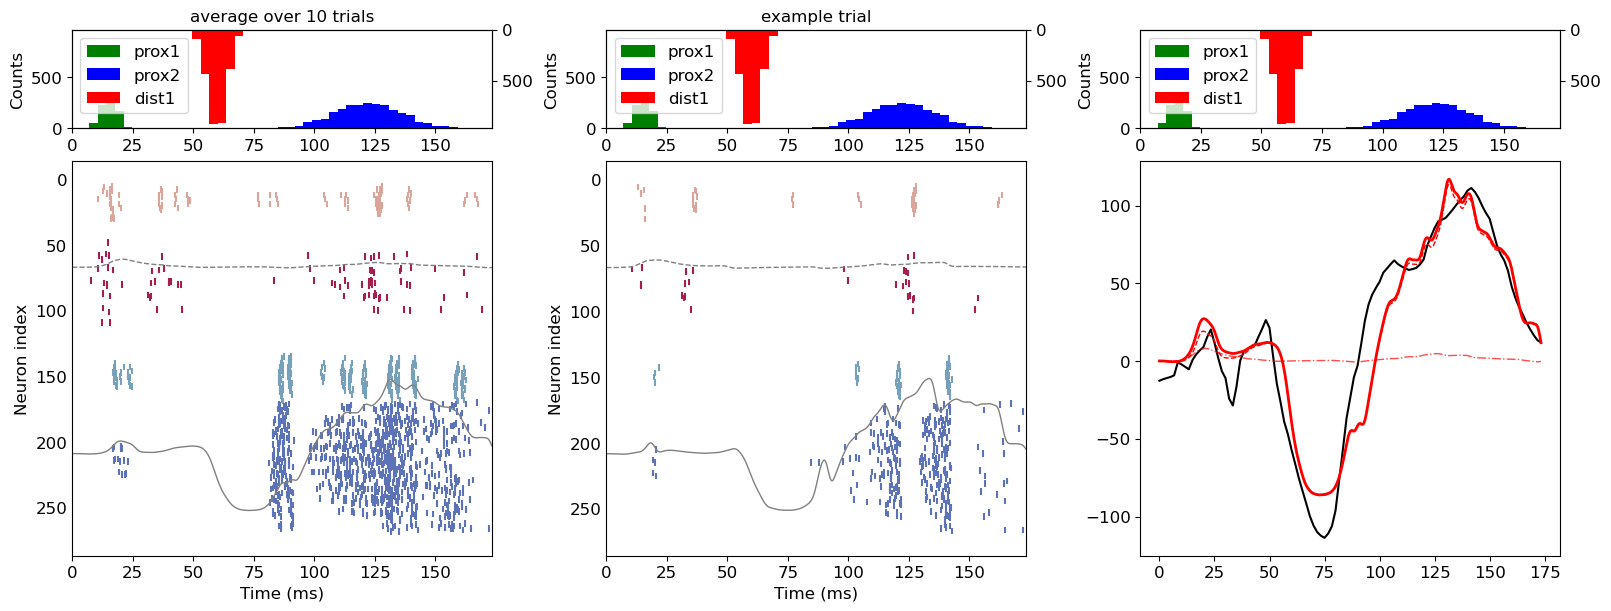

In [10]:
fig, ax = plt.subplots(2,3, figsize=(16,6), height_ratios=[0.25, 1], constrained_layout=True)

for i in range(3):
    net.cell_response.plot_spikes_hist(ax=ax[0,i], show=False, invert_spike_types='dist1')
net.cell_response.plot_spikes_raster(ax=ax[1,0], show=False, overlay_dipoles=True, dpl=dpl, show_legend=False)
net.cell_response.plot_spikes_raster(ax=ax[1,1], trial_idx=2, show=False, overlay_dipoles=True, dpl=dpl[0], show_legend=False)

ax[0,0].set_title('average over 10 trials')
ax[0,1].set_title('example trial')


ax[1,2].plot(exp_dpl.times, exp_dpl.data['agg'], color='k')

ax[1,2].plot(avg_dpl.times, avg_dpl.data['L2'], linewidth=1, color='r', alpha=0.7, linestyle='-.', label='L2')
ax[1,2].plot(avg_dpl.times, avg_dpl.data['L5'], linewidth=1, color='r', label='L5', linestyle='--')
ax[1,2].plot(avg_dpl.times, avg_dpl.data['agg'], linewidth=2, color='r')
